# Symulacja portfela akcji

Nasz portfel składa się z trzech akcji o dziennych zwrotach $R_1, R_2, R_3 \sim N(\mu_i, \sigma_i^2)$
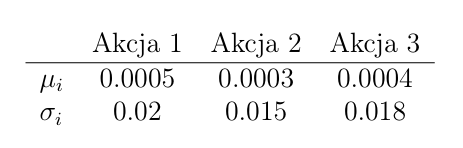

## Scenariusz 1.

Zakładamy silną korelację - akcje z tego samego sektora.

$$\rho_A = \begin{bmatrix}
1 & 0.85 & 0.75 \\
0.85 & 1 & 0.70 \\
0.75 & 0.70 & 1
\end{bmatrix}$$ 

In [ ]:
import numpy as np 
import scipy 
import matplotlib.pyplot as plt 
from decimal import Decimal
from list_3_func import box_muller

def generate_correlated_normal(means, variances, corr_matrix, size=100000):
    """
    Generuje wektory o wielowymiarowym rozkładzie normalnym 
    przy użyciu dekompozycji Cholesky'ego.
    """
    # dekompozycja macierzy korelacji
    L = np.linalg.cholesky(corr_matrix)
    
    # generowanie niezależnych zmiennych N(0, 1)
    # size to liczba próbek, len(means) to liczba zmiennych (np. 3 akcje)
    Z = np.array([box_muller(size) for _ in range(len(means))])
    
    # Nadanie korelacji
    X = L @ Z
    
    # skalowanie i przesunięcie do odpowiednich średnich i wariancji
    X_final = X * np.sqrt(variances)[:, np.newaxis] + means[:, np.newaxis]
    
    return X_final

def portfolio_return(weights, returns):
    """
    Oblicza zwrot portfela jako ważoną sumę zwrotów poszczególnych aktywów.
    weights: wektor wag (np. [0.5, 0.3, 0.2])
    returns: macierz zwrotów (każdy wiersz to zwroty dla jednego aktywa)
    """
    return np.dot(weights, returns)

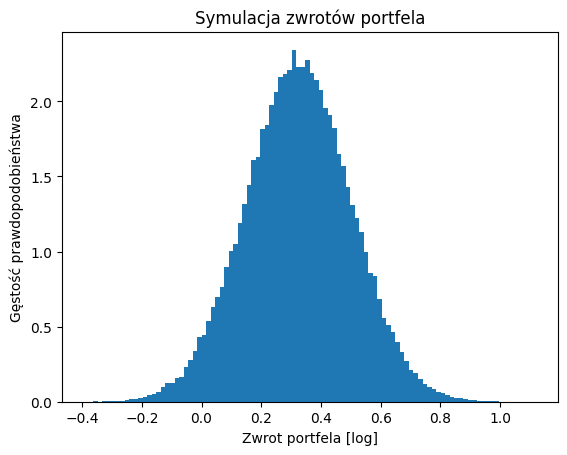

In [34]:
corr_matrix = np.array([[1, 0.85, 0.75],
                        [0.85, 1, 0.7],
                        [0.75, 0.7, 1]])
means = np.array([0.0005, 0.0003, 0.0004])
variances = np.array([0.02, 0.015, 0.018])
a_scenario = generate_correlated_normal(means, variances, corr_matrix)
portfolio_return_a = portfolio_return([0.5, 0.3, 0.2], a_scenario)

portfolio_return_pct = portfolio_return_a
plt.hist(portfolio_return_pct, bins=100, density=True)
plt.title("Symulacja zwrotów portfela")
plt.xlabel("Zwrot portfela [log]")
plt.ylabel("Gęstość prawdopodobieństwa")
plt.show()

In [ ]:
print(portfolio_return_a.mean(), portfolio_return_a.std())

0.32442253984128155 0.17652750392331734


In [36]:
print(scipy.stats.mstats.mquantiles(portfolio_return_pct, prob=[0.01]))

[-0.08825883]


## Scenariusz 2 
Zakładamy brak korelacji 


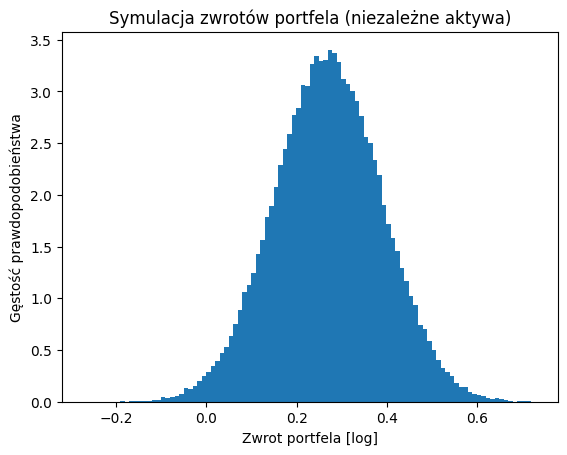

0.26962132549692547 0.11896824174544682
[-0.00837868]


In [37]:
corr_matrix = np.array([[1, 0, 0],
                        [0, 1, 0], 
                        [0, 0, 1]])
b_scenario = generate_correlated_normal(means, variances, corr_matrix)
portfolio_return_b = portfolio_return([0.5, 0.3, 0.2], b_scenario)

plt.hist(portfolio_return_b, bins=100, density=True)
plt.title("Symulacja zwrotów portfela (niezależne aktywa)")
plt.xlabel("Zwrot portfela [log]")
plt.ylabel("Gęstość prawdopodobieństwa")
plt.show()

print(portfolio_return_b.mean(), portfolio_return_b.std())
print(scipy.stats.mstats.mquantiles(portfolio_return_b, prob=[0.01]))

## Scenariusz 3. 
Zakładamy korelacje ujemne, na te same czynniki 

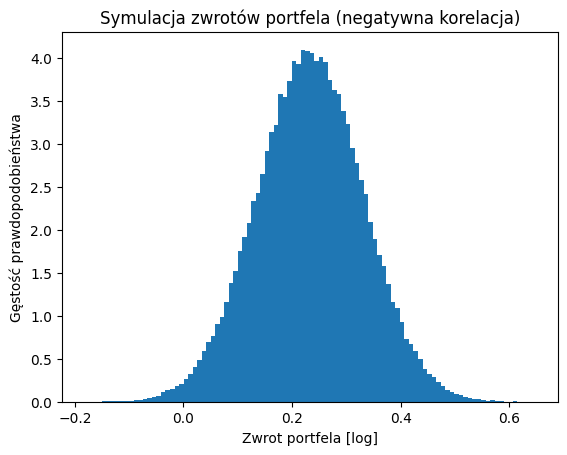

0.23322678873384492 0.09806463362162408
[0.00549626]


In [40]:
corr_matrix = np.array([[1, -0.4, -0.2],
                        [-0.4, 1, 0.3],
                        [-0.2, 0.3, 1]])
c_scenario = generate_correlated_normal(means, variances, corr_matrix)
portfolio_return_c = portfolio_return([0.5, 0.3, 0.2], c_scenario)
plt.hist(portfolio_return_c, bins=100, density=True)
plt.title("Symulacja zwrotów portfela (negatywna korelacja)")
plt.xlabel("Zwrot portfela [log]")
plt.ylabel("Gęstość prawdopodobieństwa")
plt.show()

print(portfolio_return_c.mean(), portfolio_return_c.std())
print(scipy.stats.mstats.mquantiles(portfolio_return_c, prob=[0.01]))

In [41]:
print("Porównanie scenariuszy:")
print(f"Scenariusz A - Średnia: {portfolio_return_a.mean():.4f}, Odchylenie: {portfolio_return_a.std():.4f}, VaR 1%: {scipy.stats.mstats.mquantiles(portfolio_return_a, prob=[0.01])[0]:.4f}")
print(f"Scenariusz B - Średnia: {portfolio_return_b.mean():.4f}, Odchylenie: {portfolio_return_b.std():.4f}, VaR 1%: {scipy.stats.mstats.mquantiles(portfolio_return_b, prob=[0.01])[0]:.4f}")
print(f"Scenariusz C - Średnia: {portfolio_return_c.mean():.4f}, Odchylenie: {portfolio_return_c.std():.4f}, VaR 1%: {scipy.stats.mstats.mquantiles(portfolio_return_c, prob=[0.01])[0]:.4f}")

Porównanie scenariuszy:
Scenariusz A - Średnia: 0.3244, Odchylenie: 0.1765, VaR 1%: -0.0883
Scenariusz B - Średnia: 0.2696, Odchylenie: 0.1190, VaR 1%: -0.0084
Scenariusz C - Średnia: 0.2332, Odchylenie: 0.0981, VaR 1%: 0.0055
